# 13 - Stage 2 Final Evaluation

This notebook consolidates the saved Stage 2 ablation results and evaluates the saved combined logistic and LightGBM models using the supplied PAN-12 test split. Thresholds are loaded from the training-only validation runs and are not retuned here.

It calculates test-set PR curves and class-stratified bootstrap intervals. These intervals reflect sampling uncertainty conditional on the observed test class counts, not uncertainty from source shift or model retraining.

In [1]:
from pathlib import Path
import json
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    average_precision_score, precision_recall_curve, roc_auc_score,
    precision_score, recall_score, f1_score, confusion_matrix,
)

RANDOM_SEED = 42
BOOTSTRAP_REPLICATES = 200
BATCH_SIZE = 500
WORKSPACE = Path.cwd()
FEATURES_DIR = WORKSPACE / "data" / "processed"
REPORT_DIR = WORKSPACE / "reports"
MODEL_DIR = WORKSPACE / "models"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

required_paths = [
    FEATURES_DIR / "pan12_conversation_features.csv",
    MODEL_DIR / "stage2_logistic_all.joblib",
    MODEL_DIR / "stage2_lightgbm_all_numeric.joblib",
    REPORT_DIR / "stage2_ablation_results.csv",
    REPORT_DIR / "stage2_lightgbm_results.csv",
    REPORT_DIR / "stage2_ablation_thresholds.json",
    REPORT_DIR / "stage2_lightgbm_thresholds.json",
]
missing_paths = [path for path in required_paths if not path.exists()]
if missing_paths:
    raise FileNotFoundError("Required outputs are missing: " + ", ".join(str(path) for path in missing_paths))

conversations = pd.read_csv(required_paths[0])
conversations["conversation_text"] = conversations["conversation_text"].fillna("")
test_frame = conversations.loc[conversations["split"] == "test"].copy()
if test_frame.empty or test_frame["label"].nunique() != 2:
    raise ValueError("The supplied test split must contain both label classes.")

stage_columns = [
    column for column in [
        "fraction_predicted_200", "fraction_predicted_600", "fraction_predicted_900",
        "stage_600_threshold_onset", "stage_900_threshold_onset",
        "mean_stage_600_probability", "mean_stage_900_probability",
        "max_stage_600_probability", "max_stage_900_probability",
    ] if column in conversations.columns
]
behavioral_columns = [
    column for column in conversations.columns
    if column not in {"split", "conversation_id", "conversation_text", "label", *stage_columns}
]
numeric_columns = stage_columns + behavioral_columns
y_test = test_frame["label"].to_numpy(dtype=int)
print("Test conversations:", len(test_frame))
print("Test class counts:", dict(pd.Series(y_test).value_counts().sort_index()))

Test conversations: 155128
Test class counts: {0: np.int64(151391), 1: np.int64(3737)}


## Load thresholds and score the test set

Predictions are processed in batches to limit text-vectorization memory use.

In [2]:
logistic_model = joblib.load(MODEL_DIR / "stage2_logistic_all.joblib")
lightgbm_model = joblib.load(MODEL_DIR / "stage2_lightgbm_all_numeric.joblib")
logistic_threshold = json.loads((REPORT_DIR / "stage2_ablation_thresholds.json").read_text(encoding="utf-8"))["all"]
lightgbm_threshold = json.loads((REPORT_DIR / "stage2_lightgbm_thresholds.json").read_text(encoding="utf-8"))["all_numeric"]

def batched_positive_probability(model, frame, feature_columns=None):
    outputs = []
    for start in range(0, len(frame), BATCH_SIZE):
        batch = frame.iloc[start:start + BATCH_SIZE]
        model_input = batch if feature_columns is None else batch[feature_columns]
        outputs.append(model.predict_proba(model_input)[:, 1])
    return np.concatenate(outputs)

logistic_scores = batched_positive_probability(logistic_model, test_frame)
lightgbm_scores = batched_positive_probability(lightgbm_model, test_frame, numeric_columns)
print("Scored test rows:", len(logistic_scores), len(lightgbm_scores))
print("Frozen thresholds:", {"logistic_all": logistic_threshold, "lightgbm_all_numeric": lightgbm_threshold})

Scored test rows: 155128 155128
Frozen thresholds: {'logistic_all': 0.8947203886773488, 'lightgbm_all_numeric': 0.9122831304450195}


## Metrics and bootstrap intervals

Each bootstrap resample retains the observed number of positives and negatives. Thresholded precision, recall, and F1 use the frozen validation threshold.

In [3]:
def evaluate_scores(name, scores, threshold, labels, replicates=BOOTSTRAP_REPLICATES):
    predictions = (scores >= threshold).astype(int)
    observed = {
        "model": name,
        "threshold": float(threshold),
        "pr_auc": average_precision_score(labels, scores),
        "roc_auc": roc_auc_score(labels, scores),
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions, zero_division=0),
        "f1": f1_score(labels, predictions, zero_division=0),
    }
    negatives = np.flatnonzero(labels == 0)
    positives = np.flatnonzero(labels == 1)
    rng = np.random.default_rng(RANDOM_SEED)
    bootstrap_metrics = {key: [] for key in ["pr_auc", "roc_auc", "precision", "recall", "f1"]}
    for _ in range(replicates):
        sample_indices = np.concatenate([
            rng.choice(negatives, size=len(negatives), replace=True),
            rng.choice(positives, size=len(positives), replace=True),
        ])
        sample_labels = labels[sample_indices]
        sample_scores = scores[sample_indices]
        sample_predictions = (sample_scores >= threshold).astype(int)
        values = {
            "pr_auc": average_precision_score(sample_labels, sample_scores),
            "roc_auc": roc_auc_score(sample_labels, sample_scores),
            "precision": precision_score(sample_labels, sample_predictions, zero_division=0),
            "recall": recall_score(sample_labels, sample_predictions, zero_division=0),
            "f1": f1_score(sample_labels, sample_predictions, zero_division=0),
        }
        for metric, value in values.items():
            bootstrap_metrics[metric].append(value)

    for metric, values in bootstrap_metrics.items():
        low, high = np.quantile(values, [0.025, 0.975])
        observed[f"{metric}_ci_low"] = float(low)
        observed[f"{metric}_ci_high"] = float(high)
    tn, fp, fn, tp = confusion_matrix(labels, predictions, labels=[0, 1]).ravel()
    observed.update({"true_negative": int(tn), "false_positive": int(fp), "false_negative": int(fn), "true_positive": int(tp)})
    return observed

evaluation_results = pd.DataFrame([
    evaluate_scores("logistic_all", logistic_scores, logistic_threshold, y_test),
    evaluate_scores("lightgbm_all_numeric", lightgbm_scores, lightgbm_threshold, y_test),
])
display(evaluation_results)
evaluation_results.to_csv(REPORT_DIR / "stage2_final_evaluation.csv", index=False)
evaluation_results.to_json(REPORT_DIR / "stage2_final_evaluation.json", orient="records", indent=2)

,model,threshold,pr_auc,roc_auc,precision,recall,f1,pr_auc_ci_low,pr_auc_ci_high,roc_auc_ci_low,...,precision_ci_low,precision_ci_high,recall_ci_low,recall_ci_high,f1_ci_low,f1_ci_high,true_negative,false_positive,false_negative,true_positive
0,logistic_all,0.894720,0.747965,0.990301,0.705251,0.650522,0.676782,0.736014,0.760713,0.989534,...,0.692971,0.717885,0.636072,0.666858,0.665736,0.690530,150375,1016,1306,2431
1,lightgbm_all_numeric,0.912283,0.565975,0.968115,0.583445,0.465882,0.518078,0.553499,0.583808,0.966615,...,0.566193,0.597557,0.451699,0.483309,0.506336,0.532041,150148,1243,1996,1741


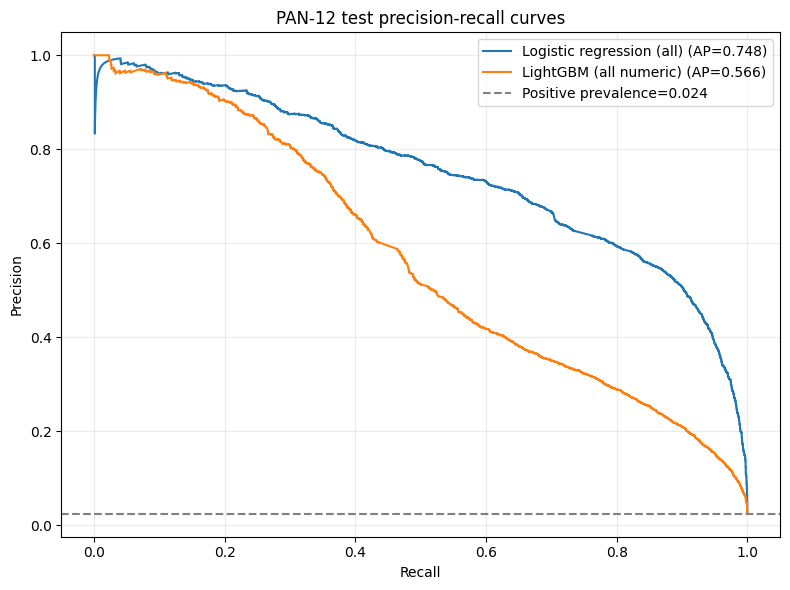

,variant,threshold,pr_auc,roc_auc,precision,recall,f1,model_family
0,text_only,0.812739,0.742247,0.984440,0.702305,0.676746,0.689289,Logistic regression
1,stage_only,0.761646,0.105359,0.686303,0.180785,0.242708,0.207220,Logistic regression
2,behavior_only,0.874426,0.210908,0.893933,0.259516,0.290072,0.273945,Logistic regression
3,all,0.894720,0.747965,0.990301,0.705251,0.650522,0.676782,Logistic regression
4,stage_only,0.844819,0.303866,0.864434,0.349525,0.344661,0.347076,LightGBM
5,behavior_only,0.881573,0.459547,0.955919,0.380990,0.510570,0.436364,LightGBM
6,all_numeric,0.912283,0.565975,0.968115,0.583445,0.465882,0.518078,LightGBM


In [4]:
plt.figure(figsize=(8, 6))
for model_name, scores in [("Logistic regression (all)", logistic_scores), ("LightGBM (all numeric)", lightgbm_scores)]:
    precision, recall, _ = precision_recall_curve(y_test, scores)
    ap = average_precision_score(y_test, scores)
    plt.plot(recall, precision, label=f"{model_name} (AP={ap:.3f})")
prevalence = float(y_test.mean())
plt.axhline(prevalence, linestyle="--", color="gray", label=f"Positive prevalence={prevalence:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("PAN-12 test precision-recall curves")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(REPORT_DIR / "stage2_final_precision_recall.png", dpi=160)
plt.show()

logistic_ablation = pd.read_csv(REPORT_DIR / "stage2_ablation_results.csv").assign(model_family="Logistic regression")
lightgbm_ablation = pd.read_csv(REPORT_DIR / "stage2_lightgbm_results.csv").assign(model_family="LightGBM")
ablation_comparison = pd.concat([logistic_ablation, lightgbm_ablation], ignore_index=True)
display(ablation_comparison)
ablation_comparison.to_csv(REPORT_DIR / "stage2_all_ablation_comparison.csv", index=False)

## Interpretation and limitations

* PR-AUC should be interpreted relative to the test positive prevalence shown above; the dataset is highly imbalanced.
* The held-out PAN-12 split is a dataset-specific benchmark, not an estimate of performance on ordinary real-world conversations.
* Results can reflect source, author, or decoy-sting artifacts. The confidence intervals do not account for those sources of distribution shift.
* A false positive can cause harm or loss of trust. Model scores are only prompts for careful human review, never a conclusion about a person.
* Stage 1 labels exist only in the coded conversations; PAN-12 has no stage ground truth. Stage probabilities and SHAP values are model-derived signals, not verified evidence of a stage.